# Ablations and native export parity: method in practice

**Level:** 2  
**Prerequisites:** Ablations and native export parity level 1  
**Reading time:** 25 minutes

**Question:** How do fresh M03 and M04 policy runs behave on the C07 cancellation task?


## Objectives

For level 2 of ablation and native export parity on C07, Distinguish two different questions: For level 2 of ablation and native export parity on C07, whether a controller component changes task outcomes, and whether an exported scorer reproduces its reference numerically. For level 2 of ablation and native export parity on C07, Ablation and numerical parity have separate estimands and neither alone establishes general intelligence or superiority.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 2 of ablation and native export parity on C07, The notebook reads committed product artifacts. For level 2 of ablation and native export parity on C07, Owner: For level 2 of ablation and native export parity on C07, Neuraxis. For level 2 of ablation and native export parity on C07, Repository: For level 2 of ablation and native export parity on C07, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 2 of ablation and native export parity on C07, Apache-2.0. For level 2 of ablation and native export parity on C07, The JSON is a first-party, frozen experiment artifact; For level 2 of ablation and native export parity on C07, no external benchmark data are redistributed in this notebook.

For level 2 of ablation and native export parity on C07, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 2 of ablation and native export parity on C07, The method run uses an isolated Reflexmesh case workspace. For level 2 of ablation and native export parity on C07, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 2 of ablation and native export parity on C07, The release manifest verifies asset hashes. For level 2 of ablation and native export parity on C07, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 2 of ablation and native export parity on C07, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/research.json`
- `docs/evaluation/corrected-results.json`
- `data/derived/episodes/M03-C07-nominal-40000.json`
- `data/derived/episodes/M04-C07-nominal-40000.json`
- `data/derived/episodes/M11-C07-nominal-40000.json`
- `data/derived/episodes/M12-C07-nominal-40000.json`


## Method

For level 2 of ablation and native export parity on C07, An ablation asks whether removing one declared component changes an outcome under the tested protocol. For level 2 of ablation and native export parity on C07, The four Neuraxis M12 ablations preserve the same 1,160 of 1,200 core successes as the full method, so these experiments show no measured success contribution for memory, effects, deferral or invalidation. For level 2 of ablation and native export parity on C07, That equality is not proof that the components never matter; For level 2 of ablation and native export parity on C07, the case suite may not create the needed opportunities. For level 2 of ablation and native export parity on C07, Export parity instead compares native predictions with reference values over a finite vector set and a stated tolerance. For level 2 of ablation and native export parity on C07, Passing parity reduces implementation-drift risk for those inputs, but says nothing about calibration, task success, robustness, authority checks or untested values. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, Ablation estimates component contribution only when the full and reduced controllers share matched cases, seeds and budgets, and the removed component is the sole controlled difference. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, If every ablation reproduces the full outcome, the experiment shows no observed marginal contribution on this task suite. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, it does not prove the component is universally useless. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, Numerical export parity asks whether native outputs approximate a reference implementation within a declared tolerance, which is a different estimand from task success or causal contribution. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, Record the tested input domain, precision, tolerance and worst absolute error. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, a small maximum error on sampled states does not guarantee safe behavior outside that domain. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, A strong conclusion separates behavioral ablation, numerical parity and end-to-end task outcomes, and names the evidence each supports without using one as a substitute for another. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, For this level, preserve paired task identifiers and inputs across full and reduced controllers, then report outcome deltas separately from numerical export errors. For level 2 of ablation and native export parity on C07, At level 2, for ablation and native export parity on C07, A useful extension adds inputs near decision boundaries and outside the training range while preserving the tolerance before interpreting parity as deployment evidence.


### ablation and native export parity · level 2 — Verify the audit and each trace's bytes before interpreting outcomes.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04", "M11", "M12"]
trace_methods = ["M03", "M04", "M11", "M12"]
sample_case = "C07"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### ablation and native export parity · level 2 — Execute the released policies and compare the run


### ablation and native export parity · level 2 — Compare the full sequence, not only the first action


### ablation and native export parity · L2 — Build the first executable policy

In level 2, construct policy M03 for ablation and native export parity with the public factory and keep its observation contract unchanged before sampling C07.


In [3]:
# Construct the first released policy through the public factory.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M03


### ablation and native export parity · L2 — Execute the primary method on the named case

At level 2, the ablation and native export parity evaluator runs M03 on C07 and derives success from the independent task postcondition, not from a replayed trace.


In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### ablation and native export parity · L2 — Construct an independent comparison policy

For level 2 of ablation and native export parity, create M04 as a fresh object so recurrent state from M03 cannot leak into the matched comparison.


In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### ablation and native export parity · L2 — Run the comparison under identical conditions

This level 2 comparison runs M04 on the same C07, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### ablation and native export parity · L2 — Aggregate the two executed episodes

At level 2, the package aggregator summarizes two executed ablation and native export parity episodes, and cross-family claims still require the complete benchmark below.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### ablation and native export parity · L2 — Fresh policy outcomes

For level 2 of ablation and native export parity on C07, The next plot is computed from the ablation and native export parity episode results just executed for C07 rather than copied from a frozen artifact.


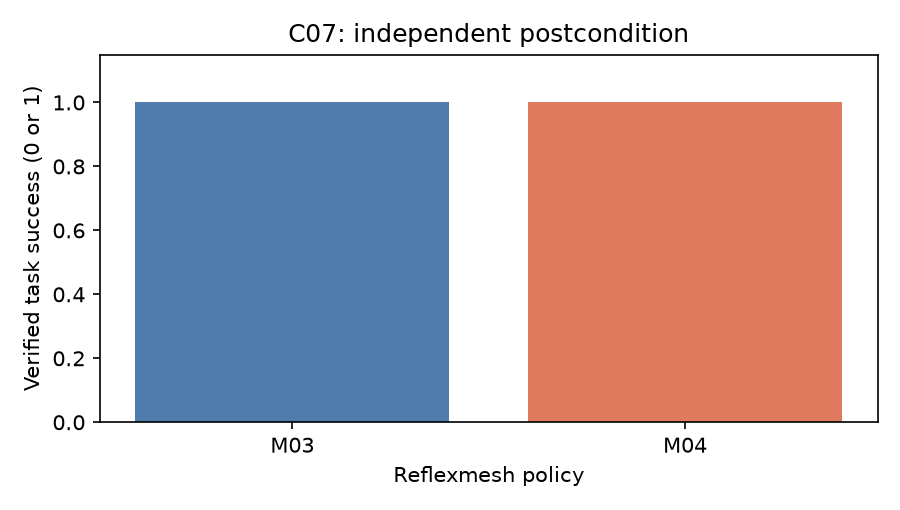

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 2 of ablation and native export parity on C07, For ablation and native export parity, these bars show fresh task-postcondition outcomes for M03 and M04 on C07, with success encoded as 1 and failure as 0. For level 2 of ablation and native export parity on C07, Read the case and seed before comparing them. For level 2 of ablation and native export parity on C07, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


### ablation and native export parity · L2 — Recorded controller time

At level 2, the ablation and native export parity timing chart uses hash-verified frozen records for M03 and M04 on C07, not machine-dependent timings from fresh episodes. This level 2 ablation and native export parity view describes the recorded environment under its declared case, variant and seed.

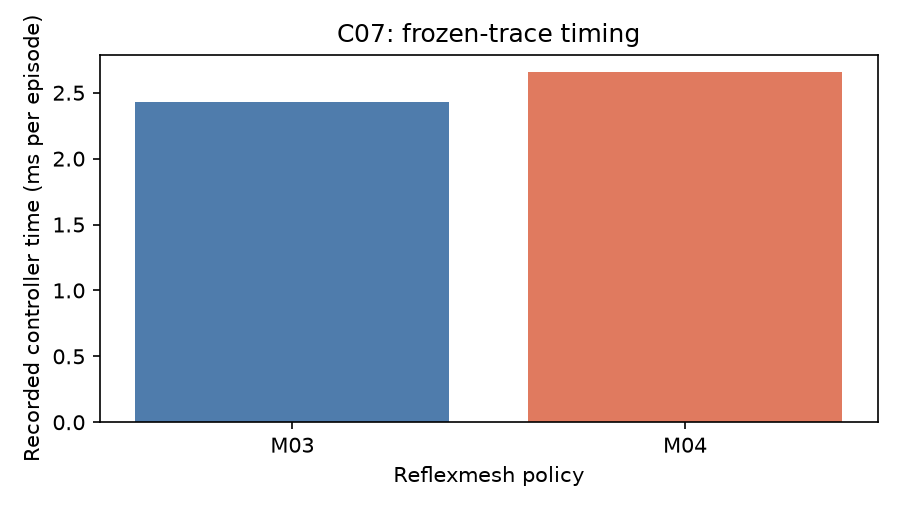

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: frozen-trace timing")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 2 ablation and native export parity chart reads canonical M03/M04 records for C07, nominal variant and seed 40000 after the data boundary verifies their hashes. For this ablation and native export parity lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The ablation and native export parity comparison executes 2 fresh policy episodes, M03 and M04, under identical C07 conditions; keep the ablation and native export parity family and seed strata in view because the frozen matrix contains designed, not population-sampled, tasks.

For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, All four ablations preserve the same 1,160/1,200 task successes, so this experiment does not show success contribution by memory, effects, deferral or invalidation. For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, Runtime budgets differ across variants, and measured export timings exclude Python feature construction. For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, For level 2 of ablation and native export parity on C07, Numerical parity is not policy safety calibration.


## Summary

For level 2 of ablation and native export parity on C07, At level 2, ablation and native export parity uses C07 to show how the released method behaves under one declared condition. For level 2 of ablation and native export parity on C07, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [XGB](https://arxiv.org/abs/1603.02754)
- [PPO](https://arxiv.org/abs/1707.06347)
